In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pymetropsis.plotting import plot_hormone_profiles

from pymetropsis.paths import DATA_DIR, FIG_DIR

In [2]:
# Load data
raw_path = DATA_DIR / "raw/clean_saliva_data.csv"
param_path = (
    DATA_DIR / "derivatives/hormones/tau_harmonics/melatonin_circadian_parameters.csv"
)

raw_data = pd.read_csv(raw_path)
param_df = pd.read_csv(param_path)

param_df = param_df[param_df["participant_id"] < 214].copy()

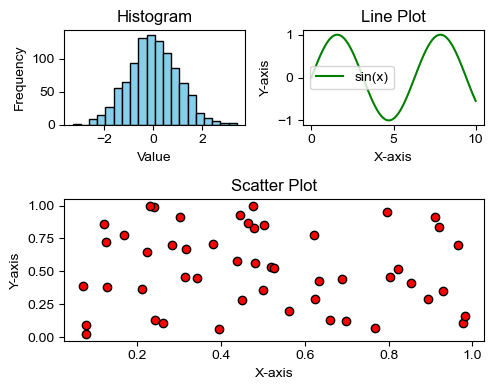

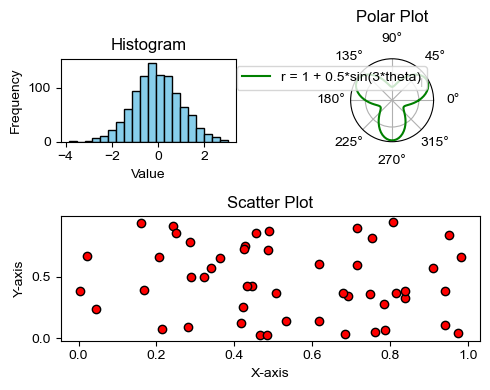

In [3]:
def three_panel_figure():
    # Create data for the plots
    data_hist = np.random.normal(loc=0, scale=1, size=1000)  # Data for histogram
    x_line = np.linspace(0, 10, 100)  # X values for line plot
    y_line = np.sin(x_line)  # Y values for line plot
    x_scatter = np.random.rand(50)  # X values for scatter plot
    y_scatter = np.random.rand(50)  # Y values for scatter plot

    # Create the figure and subplots with a grid layout
    fig = plt.figure(figsize=(5, 4))

    grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.5])  # Adjust height ratios

    # Top left: Histogram
    ax1 = fig.add_subplot(grid[0, 0])
    ax1.hist(data_hist, bins=20, color="skyblue", edgecolor="black")
    ax1.set_title("Histogram")
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Frequency")

    # Top right: Line plot
    ax2 = fig.add_subplot(grid[0, 1])
    ax2.plot(x_line, y_line, color="green", label="sin(x)")
    ax2.set_title("Line Plot")
    ax2.set_xlabel("X-axis")
    ax2.set_ylabel("Y-axis")
    ax2.legend()

    # Bottom: Scatter plot spanning the entire width
    ax3 = fig.add_subplot(grid[1, :])
    ax3.scatter(x_scatter, y_scatter, color="red", edgecolor="black")
    ax3.set_title("Scatter Plot")
    ax3.set_xlabel("X-axis")
    ax3.set_ylabel("Y-axis")

    return fig, (ax1, ax2, ax3)

fig, (ax1, ax2, ax3) = three_panel_figure()
# Adjust layout
plt.tight_layout()
plt.show()


import numpy as np
import matplotlib.pyplot as plt


def three_panel_with_polar():
    """
    Create a figure with three panels: a histogram, a polar plot, and a scatter plot.
    The scatter plot spans the entire width of the figure below the other two plots.
    """

    # Create data for the plots
    data_hist = np.random.normal(loc=0, scale=1, size=1000)  # Data for histogram
    x_scatter = np.random.rand(50)  # X values for scatter plot
    y_scatter = np.random.rand(50)  # Y values for scatter plot

    # Data for polar plot
    theta = np.linspace(0, 2 * np.pi, 100)  # Angles
    r = 1 + 0.5 * np.sin(3 * theta)  # Radius values

    # Create the figure and subplots with a grid layout
    fig = plt.figure(figsize=(5, 4))
    grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.5])  # Adjust height ratios

    # Top left: Histogram
    ax1 = fig.add_subplot(grid[0, 0])
    ax1.hist(data_hist, bins=20, color="skyblue", edgecolor="black")
    ax1.set_title("Histogram")
    ax1.set_xlabel("Value")
    ax1.set_ylabel("Frequency")

    # Top right: Polar plot
    ax2 = fig.add_subplot(grid[0, 1], projection="polar")
    ax2.plot(theta, r, color="green", label="r = 1 + 0.5*sin(3*theta)")
    ax2.set_title("Polar Plot", va="bottom")
    ax2.legend(loc="upper right")

    # Bottom: Scatter plot spanning the entire width
    ax3 = fig.add_subplot(grid[1, :])
    ax3.scatter(x_scatter, y_scatter, color="red", edgecolor="black")
    ax3.set_title("Scatter Plot")
    ax3.set_xlabel("X-axis")
    ax3.set_ylabel("Y-axis")

    # Adjust layout

    return fig, (ax1, ax2, ax3)


fig, (ax1, ax2, ax3) = three_panel_with_polar()
plt.tight_layout()
plt.show()

In [4]:
# ax.grid(True)


# Create individual melatonin plots - first participant subgroup
out_dir = "."
meldata = raw_data.merge(param_df, on="participant_id")

meldata[meldata["participant_id"] == 207]["tau"].unique().item()

23.2166666666667

In [5]:
# Select subset of columns from df
select_cols = [
    "participant_id",
    "tau",
    "mesor",
    "amplitude",
    "phase",
    "sine_component",
    "cosine_component",
    "amplitude_2",
    "phase_2",
    "sine_component_2",
    "cosine_component_2",
]
df = meldata[select_cols].drop_duplicates().reset_index(drop=True)
df

,participant_id,tau,mesor,amplitude,phase,sine_component,cosine_component,amplitude_2,phase_2,sine_component_2,cosine_component_2
0,113,24.483333,15.833304,18.802341,1.227053,-17.702400,6.336644,6.119969,2.840617,-1.814276,-5.844863
1,202,24.650000,7.676138,9.632927,1.678187,-9.577433,-1.032500,2.256842,-2.622596,1.119414,-1.959654
2,201,24.633333,8.551699,12.613353,1.724368,-12.464908,-1.929443,4.763459,-2.520904,2.770405,-3.874971
3,205,24.100000,6.520542,9.733424,1.139669,-8.842769,4.067551,4.170259,2.429316,-2.725510,-3.156368
4,204,24.066667,11.309665,15.314859,1.246034,-14.514299,4.886719,5.195972,2.880240,-1.342572,-5.019525
5,206,24.350000,7.578005,9.220313,1.488583,-9.189171,0.757176,2.179625,-2.990500,0.328074,-2.154793
6,207,23.216667,15.130460,17.355810,1.518108,-17.331724,0.914032,3.621081,-2.976336,0.595688,-3.571748
7,209,24.216667,6.170379,8.746533,1.432403,-8.662907,1.206597,2.975168,3.040854,-0.299209,-2.960084
8,211,23.916667,7.250122,11.057383,1.001523,-9.313555,5.960151,5.146187,2.084644,-4.481607,-2.529513
9,210,24.283333,2.765647,2.809553,2.033949,-2.513563,-1.255226,0.936946,-1.921857,0.879800,-0.322210


/Users/hheinrichs/Documents/projects/civibe_psychophysics/src/pymetropsis/plotting/plot_hormone_overview.py:241: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(xtick_labels)  # Label in hours


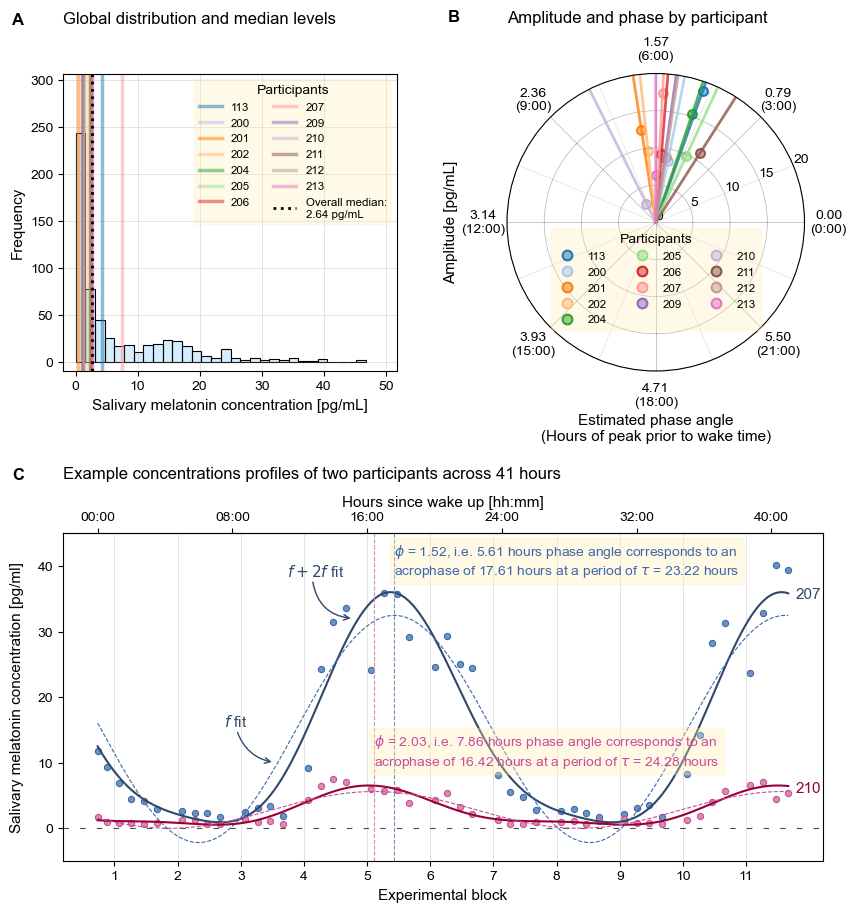

Figure saved to: /Users/hheinrichs/Documents/projects/civibe_psychophysics/reports/fig/hormones/descriptives/img_melatonin_overview_figure.pdf


In [6]:
import importlib
from pymetropsis.plotting import plot_hormone_overview
from pymetropsis.plotting.plot_utils import save_figure
importlib.reload(plot_hormone_overview)


raw_data = pd.read_csv(raw_path)
param_df = pd.read_csv(param_path)

meldata = param_df.merge(raw_data, on="participant_id")
meldata = meldata[
    (meldata["participant_id"] < 214) & (meldata["session_id"] == "FD")
].copy()

# Figure formatting
# fig.suptitle(f"Overview of melatonin parameters" fontsize=14, y=1)
fig, axes = plot_hormone_overview.create_melatonin_grid_figure(meldata=meldata)
plt.show()

out_dir = FIG_DIR / "hormones/descriptives"
save_figure(fig_name="img_melatonin_overview_figure.pdf", fig_dir=out_dir, fig=fig)

In [6]:
r = np.arange(0, 2, 0.01)
theta = 2 * np.pi * r
theta
np.arange(0, 2 * np.pi, np.pi/6)

xticks = [0.0, 0.78539816, 1.57079633, 2.35619449, 3.14159265, 3.92699082, 4.71238898, 5.49778714]
print(xticks)
# create dataframe with 3 columns: tick, tick in pi, hour
df_ticks = pd.DataFrame({
    "tick": xticks,
    "tick_in_pi": [tick / np.pi for tick in xticks],
    "hour": [tick / (2 * np.pi) * 24 for tick in xticks]
})
print(df_ticks)

print(24 / 3.75)


[0.0, 0.78539816, 1.57079633, 2.35619449, 3.14159265, 3.92699082, 4.71238898, 5.49778714]
       tick  tick_in_pi  hour
0  0.000000        0.00   0.0
1  0.785398        0.25   3.0
2  1.570796        0.50   6.0
3  2.356194        0.75   9.0
4  3.141593        1.00  12.0
5  3.926991        1.25  15.0
6  4.712389        1.50  18.0
7  5.497787        1.75  21.0
6.4


In [7]:
def transform_phase(
    old_phase,
    old_zero=(-1 * np.pi),
    old_range=(2 * np.pi),
    new_zero=(-1 * np.pi),
    new_range=(2 * np.pi),
):
    # Shift phase by pi to match the 0-2pi range
    new_phase = ((old_phase - old_zero) / old_range) * new_range + new_zero
    return new_phase

transform_phase(old_phase=-0.7853981633974398, new_zero=0, new_range=24)

9.000000000000032

In [8]:
from pymetropsis.plotting.plot_hormone_overview import transform_phase

old_phase = 0.5 * np.pi#meldata[meldata["participant_id"] == 204]["phase"].unique().item()
my_tau = 25 #meldata[meldata["participant_id"] == 204]["tau"].unique().item()
new_phase = transform_phase(
    old_phase=old_phase,
    old_range=2 * np.pi,
    old_zero=(-1 * np.pi),
    new_zero=0,
    new_range=my_tau,
)
print(old_phase)
print(new_phase)

frac = new_phase / my_tau

print(frac)

# what is a fraction of 2 pi


1.5707963267948966
18.75
0.75


In [9]:
def transform_phase(
    old_phase,
    old_zero=(-1 * np.pi),
    old_range=(2 * np.pi),
    new_zero=(-1 * np.pi),
    new_range=(2 * np.pi),
):
    # Shift phase by pi to match the 0-2pi range
    new_phase = ((old_phase - old_zero) / old_range) * new_range + new_zero
    return new_phase


phase_pi = transform_phase(
    old_phase=-1.57,
    old_zero=-np.pi,
    old_range=2 * np.pi,
    new_zero=0,
    new_range=2 * np.pi,
)
phase_pi

1.5715926535897933

In [10]:
import numpy as np


def rescale_phase(x, old_min=-np.pi, old_max=np.pi, new_min=0, new_max=2 * np.pi):
    """
    Rescale a phase estimate x from [old_min, old_max] to [new_min, new_max].

    Args:
        x (float or array-like): Value(s) in the old range.
        old_min (float): Old interval lower bound.
        old_max (float): Old interval upper bound.
        new_min (float): New interval lower bound.
        new_max (float): New interval upper bound.

    Returns:
        float or array-like: Rescaled value(s).
    """
    return new_min + ((x - old_min) / (old_max - old_min)) * (new_max - new_min)


rescale_phase(17.5, old_min=0, old_max=23.33, new_min=-np.pi, new_max=np.pi)
rescale_phase(0.61, old_min=-np.pi, old_max=np.pi, new_min=0, new_max=2*np.pi)

3.751592653589793

In [389]:
np.deg2rad(270)

4.71238898038469

In [396]:
print(np.rad2deg(-1.57), np.rad2deg(4.71))

-89.95437383553924 269.86312150661774


In [ ]:
np.mod(-1.5707963267949, 2*np.pi)
-1.5707963267949 // (2 * np.pi)